In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the dataset

In [2]:
from sklearn.datasets import fetch_california_housing
housing=fetch_california_housing(as_frame=True)
data=housing.frame
data.head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
#Inspecting the dimensions
print("Dimension:",data.shape)
print(data.columns)

Dimension: (20640, 9)
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')


In [4]:
#Saving a local copy of the dataset
data.to_csv("california_housing.csv",index=False)

# Understanding the columns

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:
data.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
#Checking for missing values
data.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [8]:
#Checking for duplicated values
print("Duplications :",data.duplicated().sum())

Duplications : 0


# Exploratry Data Analysis

1. Study the target variable

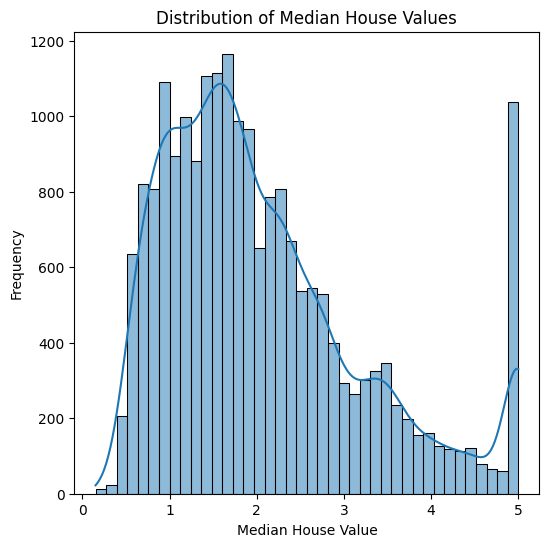

In [9]:
plt.figure(figsize=(6,6))

sns.histplot(data["MedHouseVal"],bins=40,kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

2. Relationship between income and house value

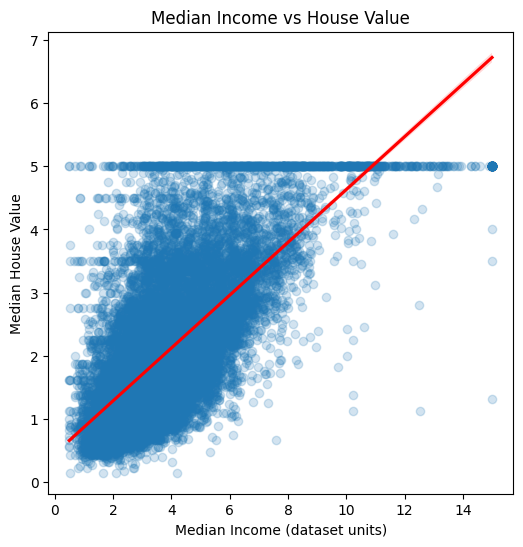

In [10]:
plt.figure(figsize=(6,6))

sns.regplot(
    data=data,
    x="MedInc",
    y="MedHouseVal",
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"})

plt.title("Median Income vs House Value")
plt.xlabel("Median Income (dataset units)")
plt.ylabel("Median House Value")

plt.show()

3. Checking Correlations

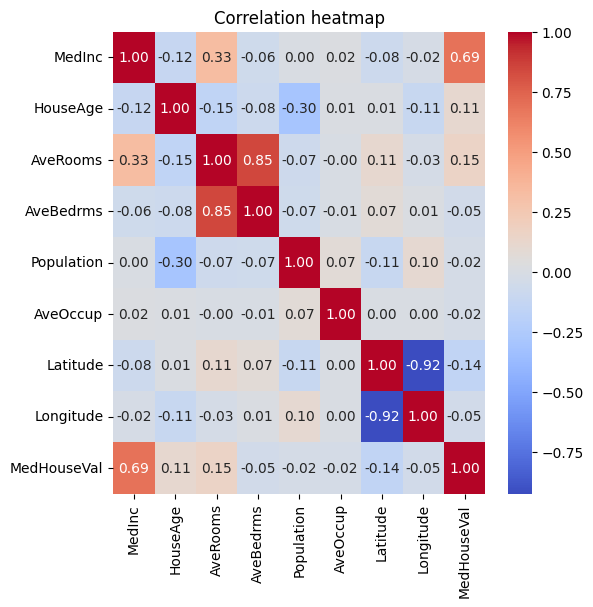

In [11]:
plt.figure(figsize=(6,6))

sns.heatmap(
    data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f")

plt.title("Correlation heatmap")
plt.show()

# Seperating Features and Target

In [12]:
x=data.drop("MedHouseVal",axis=1)
y=data["MedHouseVal"]

In [13]:
#Spliting the data
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

print("Training data",x_train.shape)
print("Test data",x_test.shape)

Training data (16512, 8)
Test data (4128, 8)


# Scaling the features

In [14]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [15]:
#Creating a evaluation function for evaluating the model's accuracy
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

def evaluate_score(model_name,y_actual,y_pred):
    mae=mean_absolute_error(y_actual,y_pred)
    mse=mean_squared_error(y_actual,y_pred)
    r2=r2_score(y_actual,y_pred)

    print(model_name)
    print("MAE:",round(mae,4))
    print("RMSE:", round(mse, 4))
    print("R2 Score:", round(r2, 4))

# Linear Regression

In [16]:
from sklearn.linear_model import LinearRegression
mlr=LinearRegression()

mlr.fit(x_train_scaled,y_train)
y_pred_mlr=mlr.predict(x_test_scaled)

evaluate_score("Linear Regression",y_test,y_pred_mlr)

Linear Regression
MAE: 0.5332
RMSE: 0.5559
R2 Score: 0.5758


# Stochastic Gradient Descent

In [17]:
from sklearn.linear_model import SGDRegressor
sgd_model=SGDRegressor(
    loss="squared_error",
    penalty=None,
    learning_rate="constant",
    eta0=0.0001,
    max_iter=3000,
    tol=None,
    shuffle=True,
    random_state=42)

sgd_model.fit(x_train_scaled,y_train)
y_pred_sgd=sgd_model.predict(x_test_scaled)

evaluate_score("Stochastic Gradient Descent",y_test,y_pred_sgd)

Stochastic Gradient Descent
MAE: 0.5335
RMSE: 0.5571
R2 Score: 0.5748


# Batch Gradient Descent

In [18]:
def batch_GD(x,y,learning_rate=0.001,epochs=1000):
    x=np.asarray(x)
    y=np.asarray(y) #converts the data into numpy array

    intercept=0
    coef=np.ones(x.shape[1])

    track_loss=[]
    for epoch in range(epochs):
        y_hat=intercept+np.dot(x,coef) #update all coefficient and intercept
        error=y-y_hat
        intercept_der= -2 *np.mean(error) #calculating intercept gradient using all rows
        intercept=intercept-(learning_rate*intercept_der) #update intercept 

        coef_der= -2 *np.dot(error,x)/x.shape[0] #calculating coefficient gradient using all rows
        coef=coef-(learning_rate*coef_der) #update coefficient

        loss=np.mean(error**2) #tracking MSE loss
        track_loss.append(loss)
        
    return intercept,coef,track_loss

- Train and Evaluate

In [19]:
bgd_intercept,bgd_coef,bgd_loss=batch_GD(
    x_train_scaled,
    y_train,
    learning_rate=0.02,
    epochs=1100)

bgd_pred=bgd_intercept+np.dot(x_test_scaled,bgd_coef)

evaluate_score("Batch Gradient Descent",y_test,bgd_pred)

Batch Gradient Descent
MAE: 0.5326
RMSE: 0.5617
R2 Score: 0.5714


- Plot the loss

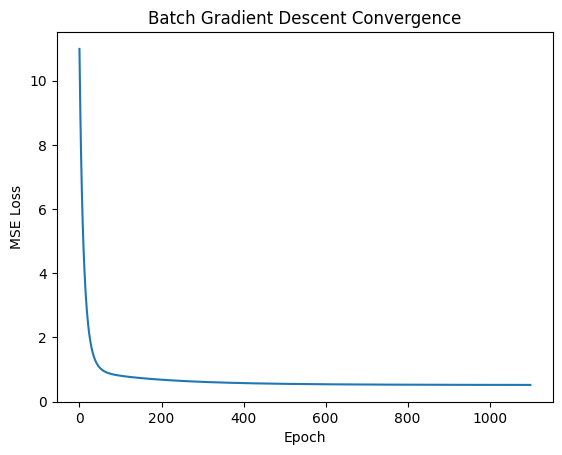

In [20]:
plt.plot(bgd_loss)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Batch Gradient Descent Convergence")

plt.show()

# Mini Batch Gradient Descent

In [21]:
sgd_model=SGDRegressor(learning_rate='constant',eta0=0.001)
batch_size=32

for epoch in range(1000):
    idx=np.random.choice(len(x_train_scaled),size=batch_size,replace=False)
    sgd_model.partial_fit(x_train_scaled[idx],y_train.iloc[idx])

y_pred_mbgd=sgd_model.predict(x_test_scaled)
evaluate_score("Mini Batch Gradient Descent",y_test,y_pred_mbgd)

Mini Batch Gradient Descent
MAE: 0.5426
RMSE: 0.5874
R2 Score: 0.5517


# Ridge Regression

In [23]:
from sklearn.linear_model import RidgeCV
alphas=[0.001,0.01,0.1,1,10,100]
ridge_model=RidgeCV(alphas=alphas,cv=5)

ridge_model.fit(x_train_scaled,y_train)
y_pred_ridge=ridge_model.predict(x_test_scaled)

evaluate_score("Ridge Regression",y_test,y_pred_ridge)
print("Best alpha:",ridge_model.alpha_)

Ridge Regression
MAE: 0.5332
RMSE: 0.5559
R2 Score: 0.5758
Best alpha: 0.001


# Lasso Regression

In [24]:
from sklearn.linear_model import LassoCV
lasso_model=LassoCV(alphas=alphas,cv=5,max_iter=10000)

lasso_model.fit(x_train_scaled,y_train)
y_pred_lasso=lasso_model.predict(x_test_scaled)

evaluate_score("Ridge Regression",y_test,y_pred_lasso)
print("Best alpha:",lasso_model.alpha_)

Ridge Regression
MAE: 0.5331
RMSE: 0.5545
R2 Score: 0.5769
Best alpha: 0.001


# Elastic Net Regression

In [26]:
from sklearn.linear_model import ElasticNetCV
elastic_model=ElasticNetCV(
    alphas=alphas,
    l1_ratio=[0.2,0.5,0.8],
    cv=5,
    max_iter=10000)

elastic_model.fit(x_train_scaled,y_train)
y_pred_elastic=elastic_model.predict(x_test_scaled)

evaluate_score("Elastic Regression",y_test,y_pred_elastic)
print("Best alpha:",elastic_model.alpha_)
print("Best l1_ratio:",elastic_model.l1_ratio_)

Elastic Regression
MAE: 0.5331
RMSE: 0.5547
R2 Score: 0.5767
Best alpha: 0.001
Best l1_ratio: 0.8


# Comparing every model

In [36]:
#predictions by each model
predictions={
    "Linear Regression": y_pred_mlr,
    "Batch Gradient Descent": bgd_pred,
    "Stochastic Gradient Descent": y_pred_sgd,
    "Mini-Batch Gradient Descent": y_pred_mbgd,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso,
    "Elastic Net Regression": y_pred_elastic}

results=[]
#calculating the MSE,RMSE,r2_score of each model
for model_name,model_pred in predictions.items():
    results.append({
        "Model Name":model_name,
        "MSE":mean_absolute_error(y_test, model_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, model_pred)),
        "R2 Score": r2_score(y_test, model_pred)
    })
    
results_df=pd.DataFrame(results)
results_df=results_df.sort_values(by="RMSE",ascending=True).reset_index(drop=True)
results_df.round(4) #converting the comparision into a dataframe

,Model Name,MSE,RMSE,R2 Score
0,Lasso Regression,0.5331,0.7446,0.5769
1,Elastic Net Regression,0.5331,0.7448,0.5767
2,Ridge Regression,0.5332,0.7456,0.5758
3,Linear Regression,0.5332,0.7456,0.5758
4,Stochastic Gradient Descent,0.5335,0.7464,0.5748
5,Batch Gradient Descent,0.5326,0.7494,0.5714
6,Mini-Batch Gradient Descent,0.5426,0.7664,0.5517


- Visualisation of the comparison

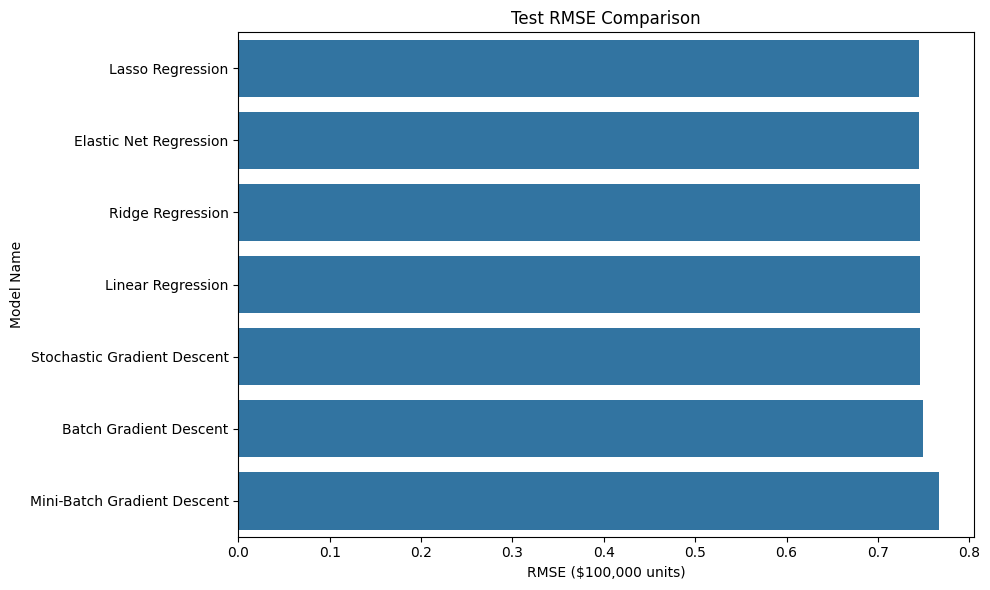

In [44]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="RMSE",
    y="Model Name"
)

plt.title("Test RMSE Comparison")
plt.xlabel("RMSE ($100,000 units)")
plt.ylabel("Model Name")

plt.tight_layout()
plt.show()

# Inspecting for the best model

- THE BEST MODEL

In [37]:
best_model_name=results_df.iloc[0]["Model Name"]
print("Best Model by RMSE:",best_model_name)

Best Model by RMSE: Lasso Regression


- COMPARING THE PREDICTIONS WITH ACTUAL VALUES

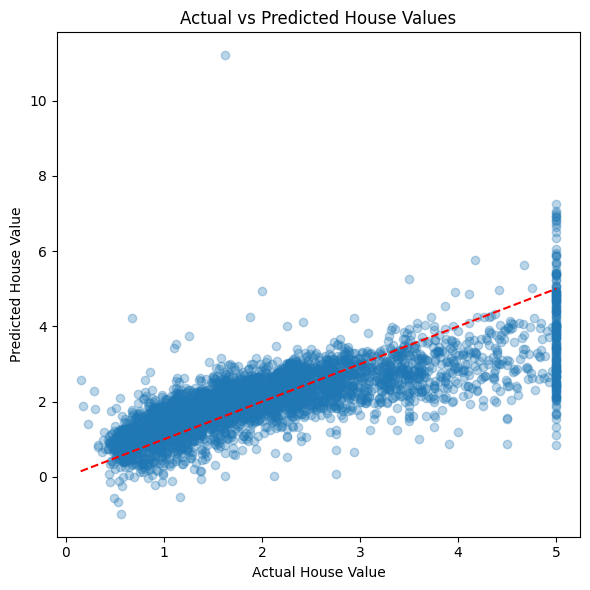

In [43]:
#Comparing the predictions of the house values by the best model from the actual house values and thereby inspecting the accuracy
#Points on the red line indicates perfect predictions and indicates error otherwise
best_pred=predictions[best_model_name]

plt.figure(figsize=(6,6))
plt.scatter(y_test, best_pred, alpha=0.3)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()], 
    [y_test.min(), y_test.max()],
    "r--"                          #red dotted line
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted House Values")

plt.tight_layout()
plt.show()

- INSPECTING THE RESIDUALS

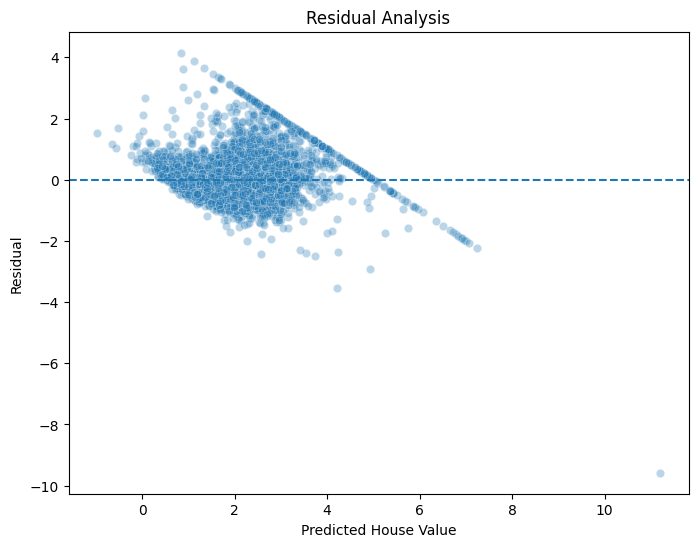

In [45]:
#This plot helps in analysing the patterns in the model's errors that reveal weaknesses
residuals=y_test-best_pred

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=best_pred,
    y=residuals,
    alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Value")
plt.ylabel("Residual")
plt.title("Residual Analysis")

plt.show()
#here horizontal dotted line at 0 indicates perfect predictions
#dots above the line indicate underestimated values
#dots below the line indicates overestimated values
#dots on the line indicates correct prediction

# Effect of Regularization

In [48]:
#coefficients calculated by each model
coefficients = pd.DataFrame({
    "Feature": x.columns,
    "Linear Regression": mlr.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_,
    "Elastic Net": elastic_model.coef_
})

coefficients.round(4)

,Feature,Linear Regression,Ridge,Lasso,Elastic Net
0,MedInc,0.8544,0.8544,0.8491,0.8500
1,HouseAge,0.1225,0.1225,0.1233,0.1234
2,AveRooms,-0.2944,-0.2944,-0.2813,-0.2833
3,AveBedrms,0.3393,0.3393,0.3260,0.3279
4,Population,-0.0023,-0.0023,-0.0011,-0.0012
5,AveOccup,-0.0408,-0.0408,-0.0399,-0.0401
6,Latitude,-0.8969,-0.8969,-0.8858,-0.8855
7,Longitude,-0.8698,-0.8698,-0.8581,-0.8579


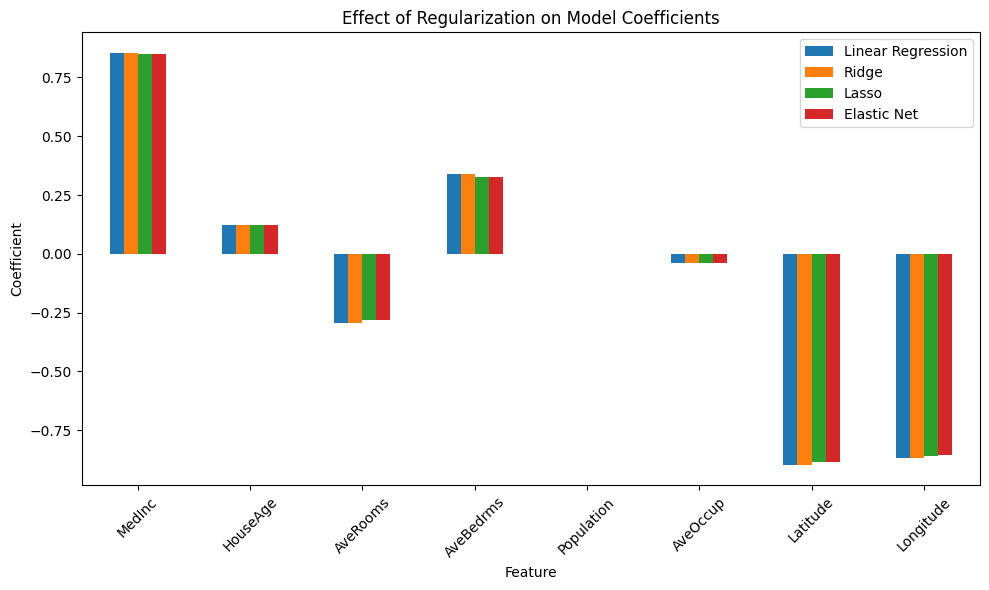

In [49]:
coefficients.set_index("Feature").plot(
    kind="bar",
    figsize=(10, 6)
) #using featuees as points on the x-axis instead of row numbers

plt.title("Effect of Regularization on Model Coefficients")
plt.ylabel("Coefficient")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [50]:
#saving the images
results_df.to_csv("model_comparison.csv", index=False) 

coefficients.to_csv("model_coefficients.csv", index=False)